# Actividad 5 (Evaluación): CLV

## Carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_squared_error, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from sklearn.utils import resample

sns.set_style("whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
archivo = "Datos_Complementarios_CLV.xlsx"
hojas = pd.read_excel(archivo, sheet_name=None)
for nombre, d in hojas.items():
    print(nombre, d.shape)

Existencias_15_10_2026 (2951, 6)
Histórico_Entradas_SAlidas (55180, 7)
Histórico_Ventas (21632, 14)


La hoja de ventas es la que tiene información de clientes, así que el análisis se hace sobre ella. Las otras dos hojas (existencias y salidas de almacén) no traen cliente.

In [3]:
ventas = hojas["Histórico_Ventas"].copy()
ventas.columns = ventas.columns.str.strip()
ventas.head()

,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marc,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
3,CDF,CDF002643,15.10.2026,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
4,CDF,CDF002643,15.10.2026,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


## Preprocesamiento
### Nulos y duplicados

In [4]:
print(ventas.isna().sum()[lambda s: s > 0])
print("Duplicados:", ventas.duplicated().sum())
print("Líneas con precio 0:", (ventas.precio_unitario == 0).sum())

cp    492
dtype: int64
Duplicados: 185
Líneas con precio 0: 1612


Solo `cp` tiene nulos y no se usa en el análisis, así que se elimina esa columna. Los registros duplicados se quitan. Las líneas con precio 0 se dejan en el ingreso (suman 0) pero no se toman en cuenta para el precio promedio.

In [5]:
ventas = ventas.drop(columns="cp").drop_duplicates()
ventas["fecha"] = pd.to_datetime(ventas["fecha_documento"], format="%d.%m.%Y")
fecha_ref = ventas["fecha"].max()
print(ventas.shape, fecha_ref.date())

(21447, 14) 2026-10-15


### Tabla por cliente
Se resume el histórico para tener una fila por cliente.

In [6]:
g = ventas.groupby("nombre_cliente")
moda = lambda s: s.mode().iloc[0]
con_precio = ventas[ventas.precio_unitario > 0].groupby("nombre_cliente").precio_unitario.mean()

clientes = pd.DataFrame({
    "ingreso": g.total_neto.sum(),
    "compras": g.folio.nunique(),
    "unidades": g.total_unidades.sum(),
    "productos": g.articulo_id.nunique(),
    "marcas": g.marc.nunique(),
    "recencia": (fecha_ref - g.fecha.max()).dt.days,
    "antiguedad": (fecha_ref - g.fecha.min()).dt.days,
    "estado": g.estado.agg(moda),
    "marca_principal": g.marc.agg(moda),
})
clientes["precio_prom"] = con_precio
clientes.describe().T

,count,mean,std,min,25%,50%,75%,max
ingreso,1685.0,69056.137128,279258.921926,0.000000,1762.080000,6981.04000,47413.790000,8.525461e+06
compras,1685.0,3.172107,4.730636,1.000000,1.000000,1.00000,3.000000,6.600000e+01
unidades,1685.0,35.562018,226.211847,1.000000,2.000000,5.00000,16.000000,6.328000e+03
productos,1685.0,9.464095,19.691822,1.000000,2.000000,4.00000,10.000000,3.730000e+02
marcas,1685.0,1.607122,1.183295,1.000000,1.000000,1.00000,2.000000,1.400000e+01
recencia,1685.0,109.090208,84.208683,0.000000,30.000000,98.00000,175.000000,2.830000e+02
antiguedad,1685.0,174.308012,83.895206,1.000000,113.000000,189.00000,248.000000,2.830000e+02
precio_prom,1683.0,25310.046752,107347.809766,27.152973,412.851699,1129.74205,3438.371409,2.170948e+06


`ingreso` es la variable respuesta (CLV). No se incluye el ticket promedio porque es ingreso entre compras, y su relación con el ingreso sería casi automática.

### Nulos en la tabla de clientes

In [7]:
print(clientes.isna().sum()[lambda s: s > 0])
print((clientes.ingreso == 0).sum(), "clientes con ingreso 0")

precio_prom    2
dtype: int64
2 clientes con ingreso 0


Los clientes sin precio promedio y con ingreso 0 solo recibieron productos sin costo. No aportan al CLV y además el logaritmo no se puede calcular con 0, así que se eliminan.

In [8]:
clientes = clientes[(clientes.ingreso > 0)].dropna(subset=["precio_prom"])
print(clientes.shape)

(1683, 10)


### Transformación y outliers
Las variables numéricas tienen mucho sesgo a la derecha (pocos clientes concentran casi todo el ingreso), por lo que se aplica logaritmo.

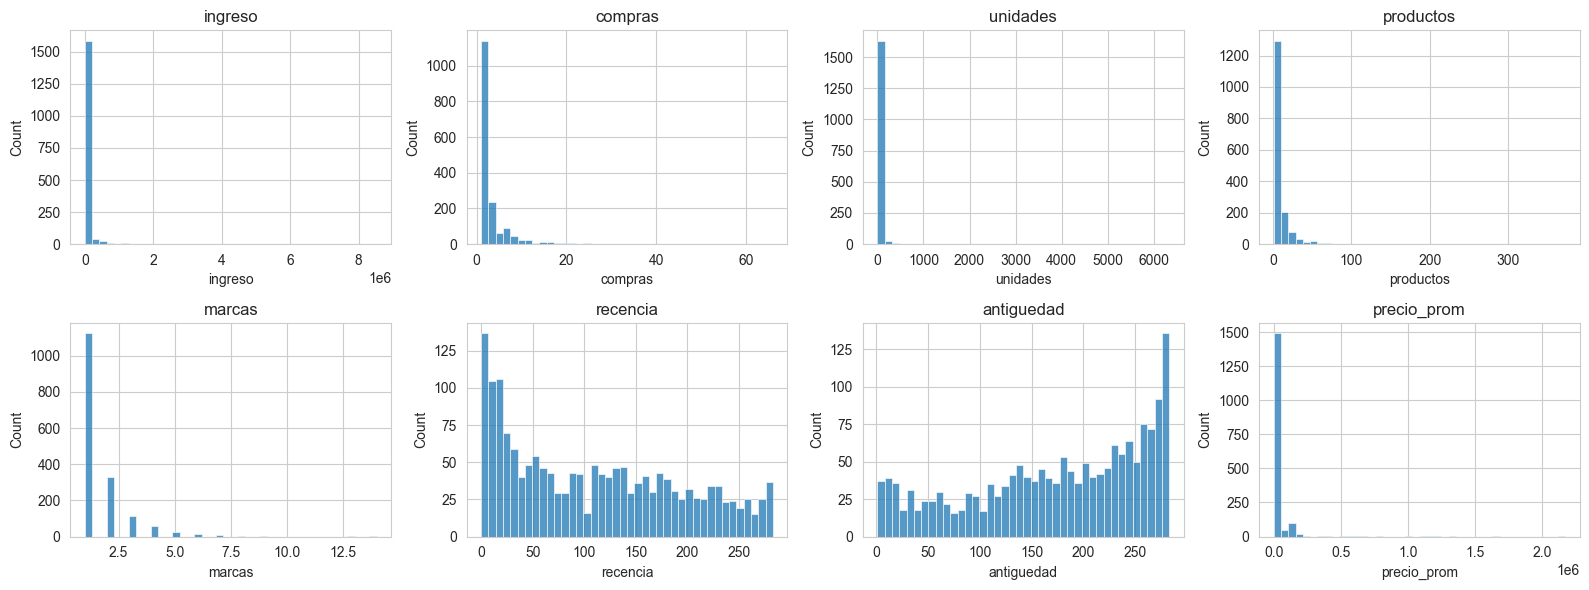

ingreso        18.83
compras         4.99
unidades       18.87
productos       9.06
marcas          3.34
recencia        0.40
antiguedad     -0.50
precio_prom    11.26
dtype: float64


In [9]:
num = ["ingreso", "compras", "unidades", "productos", "marcas", "recencia", "antiguedad", "precio_prom"]
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for a, c in zip(ax.ravel(), num):
    sns.histplot(clientes[c], bins=40, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()
print(clientes[num].skew().round(2))

In [10]:
clientes["log_ingreso"] = np.log(clientes.ingreso)
for c in num[1:]:
    clientes["log_" + c] = np.log1p(clientes[c])
logs = ["log_" + c for c in num]
print(clientes[logs].skew().round(2))

log_ingreso        0.32
log_compras        1.50
log_unidades       1.18
log_productos      0.83
log_marcas         1.72
log_recencia      -1.03
log_antiguedad    -2.12
log_precio_prom    1.03
dtype: float64


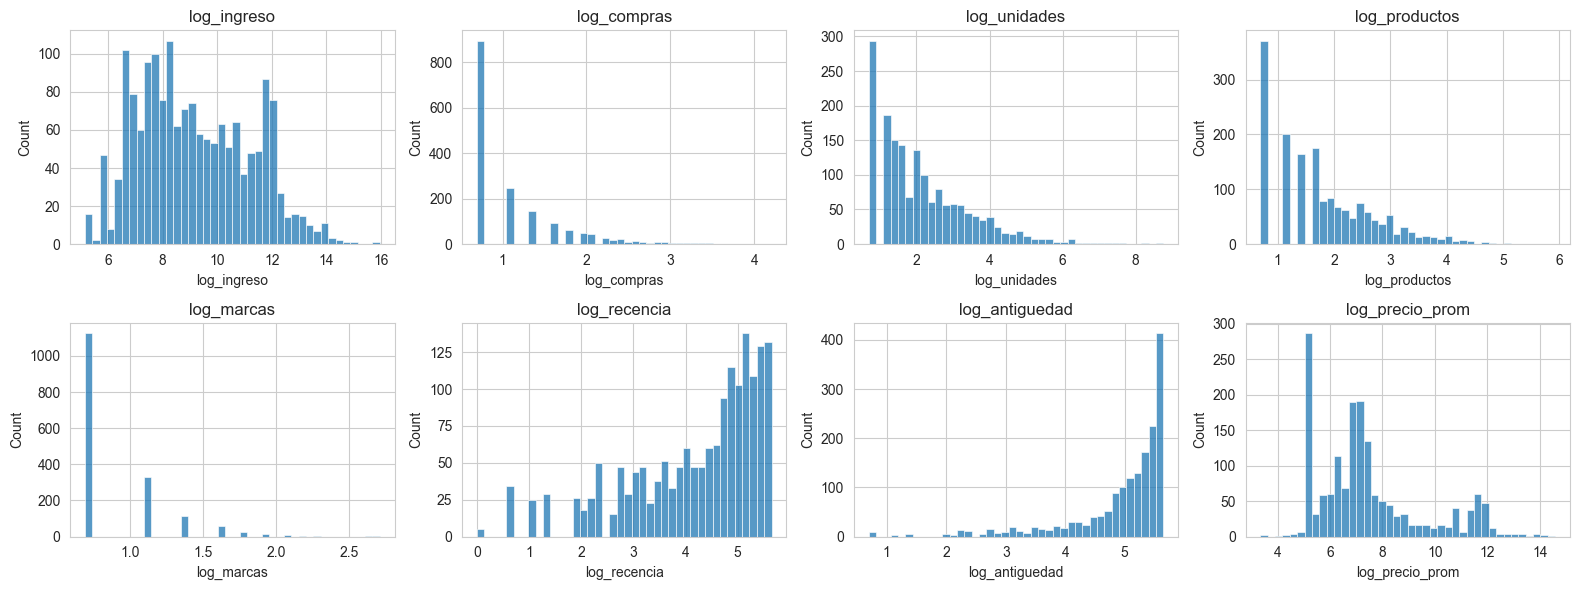

In [11]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for a, c in zip(ax.ravel(), logs):
    sns.histplot(clientes[c], bins=40, ax=a)
    a.set_title(c)
plt.tight_layout(); plt.show()

Con el logaritmo las distribuciones quedan mucho más simétricas. Para los outliers se usa el criterio del rango intercuartílico (3 veces el IQR, para quitar solo los extremos) sobre las variables ya transformadas.

In [12]:
q1 = clientes[logs].quantile(0.25)
q3 = clientes[logs].quantile(0.75)
iqr = q3 - q1
fuera = ((clientes[logs] < q1 - 3 * iqr) | (clientes[logs] > q3 + 3 * iqr))
print(fuera.sum())
print("Filas con algún outlier extremo:", fuera.any(axis=1).sum())

log_ingreso         0
log_compras         7
log_unidades        3
log_productos       0
log_marcas          2
log_recencia        0
log_antiguedad     54
log_precio_prom     1
dtype: int64
Filas con algún outlier extremo: 65


In [13]:
df = clientes[~fuera.any(axis=1)].copy()
print(clientes.shape, "->", df.shape)

(1683, 18) -> (1618, 18)


## Correlación entre variables
Primero se revisa el heatmap con las variables transformadas para decidir qué usar en los modelos.

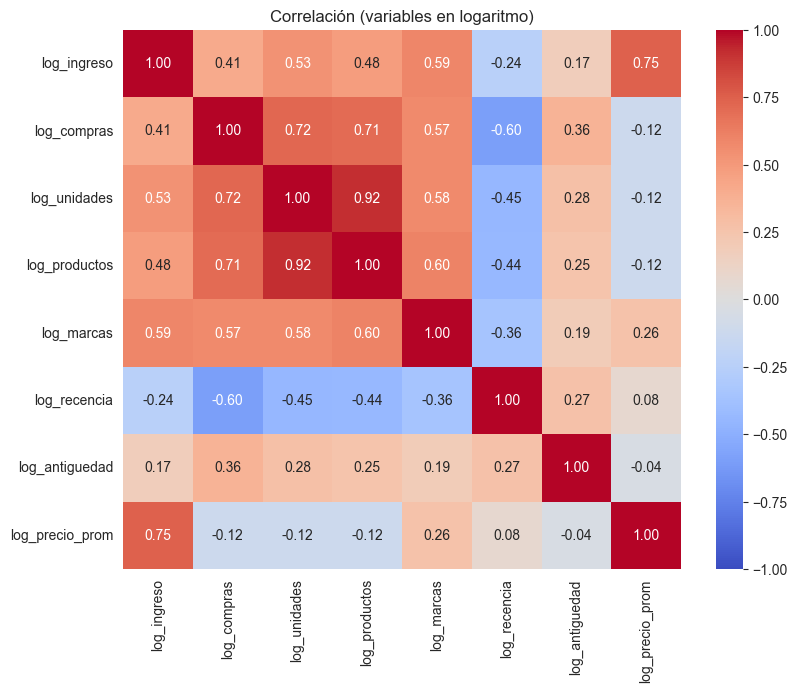

In [14]:
corr = df[logs].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación (variables en logaritmo)")
plt.show()

In [15]:
corr["log_ingreso"].drop("log_ingreso").sort_values(ascending=False).round(3)

log_precio_prom    0.747
log_marcas         0.592
log_unidades       0.534
log_productos      0.481
log_compras        0.409
log_antiguedad     0.173
log_recencia      -0.243
Name: log_ingreso, dtype: float64

- `log_precio_prom` es la que más se relaciona con el ingreso (r = 0.75), seguida de `log_marcas`, `log_unidades`, `log_productos` y `log_compras`.
- `log_unidades` y `log_productos` están muy correlacionadas entre sí, así que juntas meterían redundancia en el modelo múltiple.
- `log_recencia` tiene correlación negativa con el ingreso: los clientes que compraron hace más tiempo gastan menos.

Para el modelo simple se toma la variable con mayor correlación con `log_ingreso`. En el múltiple se parte de todas las demás y se depuran.

## Regresión lineal simple

In [16]:
mejor = corr["log_ingreso"].drop("log_ingreso").abs().idxmax()
print("Variable elegida:", mejor, "| r =", round(corr.loc[mejor, "log_ingreso"], 3))

Variable elegida: log_precio_prom | r = 0.747


In [17]:
X = sm.add_constant(df[[mejor]])
simple = sm.OLS(df["log_ingreso"], X).fit()
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:            log_ingreso   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                     2039.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          1.04e-288
Time:                        11:57:01   Log-Likelihood:                -2769.0
No. Observations:                1618   AIC:                             5542.
Df Residuals:                    1616   BIC:                             5553.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               3.7066      0.125     

In [18]:
b0, b1 = simple.params
print(f"log_ingreso = {b0:.3f} + {b1:.3f} * {mejor}")
print(f"R2 = {simple.rsquared:.3f}   R2 ajustado = {simple.rsquared_adj:.3f}")
print(f"Error estándar residual = {np.sqrt(simple.scale):.3f}")

log_ingreso = 3.707 + 0.730 * log_precio_prom
R2 = 0.558   R2 ajustado = 0.558
Error estándar residual = 1.341


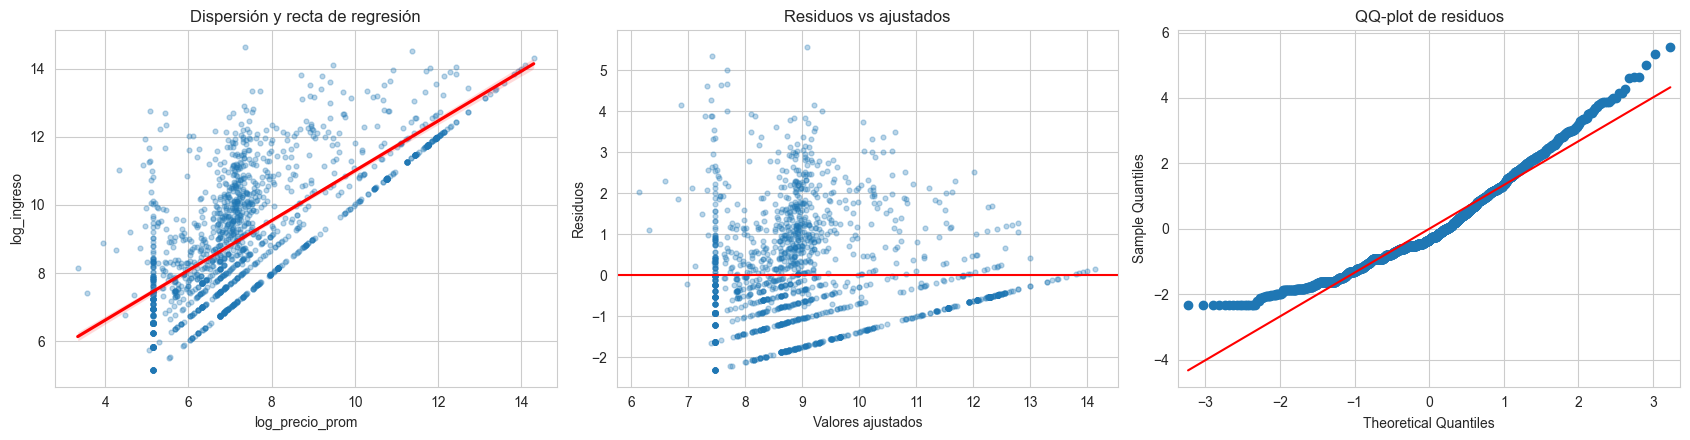

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=df[mejor], y=df["log_ingreso"], scatter_kws={"alpha": 0.3, "s": 12},
            line_kws={"color": "red"}, ax=ax[0])
ax[0].set_title("Dispersión y recta de regresión")

ax[1].scatter(simple.fittedvalues, simple.resid, alpha=0.3, s=12)
ax[1].axhline(0, color="red")
ax[1].set_xlabel("Valores ajustados"); ax[1].set_ylabel("Residuos")
ax[1].set_title("Residuos vs ajustados")

sm.qqplot(simple.resid, line="s", ax=ax[2])
ax[2].set_title("QQ-plot de residuos")
plt.tight_layout(); plt.show()

La ecuación es `log(ingreso) = 3.707 + 0.730 * log(precio_prom)`. Como las dos variables están en logaritmo, el coeficiente es una elasticidad: si el precio promedio de lo que compra el cliente sube 1%, su ingreso total sube cerca de 0.73%. El modelo explica el 55.8% de la variación (R² = 0.558) y el coeficiente es significativo (p < 0.001).

En la gráfica de dispersión se ven líneas diagonales: son clientes con una sola compra de pocas unidades, donde el ingreso depende directamente del precio. Los residuos tienen sesgo positivo (el QQ-plot se separa de la recta), así que el modelo simple es solo una referencia y deja mucha variación sin explicar.

## Regresión lineal múltiple
Se parte de todas las variables transformadas. Primero se revisa la multicolinealidad con el VIF.

In [20]:
cand = [c for c in logs if c != "log_ingreso"]

def tabla_vif(cols):
    Xv = sm.add_constant(df[cols])
    return pd.Series([variance_inflation_factor(Xv.values, i + 1) for i in range(len(cols))],
                     index=cols).sort_values(ascending=False)

tabla_vif(cand).round(2)

log_productos      7.12
log_unidades       7.05
log_compras        4.06
log_recencia       2.70
log_marcas         2.11
log_antiguedad     2.00
log_precio_prom    1.27
dtype: float64

Se quita una a una la variable con VIF más alto hasta que todas queden por debajo de 5.

In [21]:
cols = cand.copy()
while True:
    v = tabla_vif(cols)
    if v.iloc[0] <= 5:
        break
    print("Se quita", v.index[0], round(v.iloc[0], 2))
    cols.remove(v.index[0])
tabla_vif(cols).round(2)

Se quita log_productos 7.12


log_compras        4.03
log_recencia       2.70
log_unidades       2.37
log_marcas         2.01
log_antiguedad     2.00
log_precio_prom    1.26
dtype: float64

Luego se hace eliminación hacia atrás: se quita la variable con mayor p-value mientras alguna supere 0.05.

In [22]:
sel = cols.copy()
while True:
    m = sm.OLS(df["log_ingreso"], sm.add_constant(df[sel])).fit()
    p = m.pvalues.drop("const")
    if p.max() <= 0.05:
        break
    print("Se quita", p.idxmax(), round(p.max(), 3))
    sel.remove(p.idxmax())
multiple = m
print(multiple.summary())

Se quita log_recencia 0.505
Se quita log_marcas 0.065
                            OLS Regression Results                            
Dep. Variable:            log_ingreso   R-squared:                       0.962
Model:                            OLS   Adj. R-squared:                  0.961
Method:                 Least Squares   F-statistic:                 1.009e+04
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:57:02   Log-Likelihood:                -792.70
No. Observations:                1618   AIC:                             1595.
Df Residuals:                    1613   BIC:                             1622.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [23]:
# validación con partición entrenamiento / prueba
Xtr, Xte, ytr, yte = train_test_split(df[sel], df["log_ingreso"], test_size=0.25, random_state=42)
mod_m = LinearRegression().fit(Xtr, ytr)
mod_s = LinearRegression().fit(Xtr[[mejor]], ytr)
res = pd.DataFrame({
    "R2 (prueba)": [r2_score(yte, mod_s.predict(Xte[[mejor]])), r2_score(yte, mod_m.predict(Xte))],
    "RMSE (prueba)": [np.sqrt(mean_squared_error(yte, mod_s.predict(Xte[[mejor]]))),
                      np.sqrt(mean_squared_error(yte, mod_m.predict(Xte)))],
    "R2 ajustado (completo)": [simple.rsquared_adj, multiple.rsquared_adj],
    "AIC": [simple.aic, multiple.aic],
}, index=["Simple", "Múltiple"])
res.round(3)

,R2 (prueba),RMSE (prueba),R2 ajustado (completo),AIC
Simple,0.594,1.273,0.558,5542.031
Múltiple,0.953,0.433,0.961,1595.399


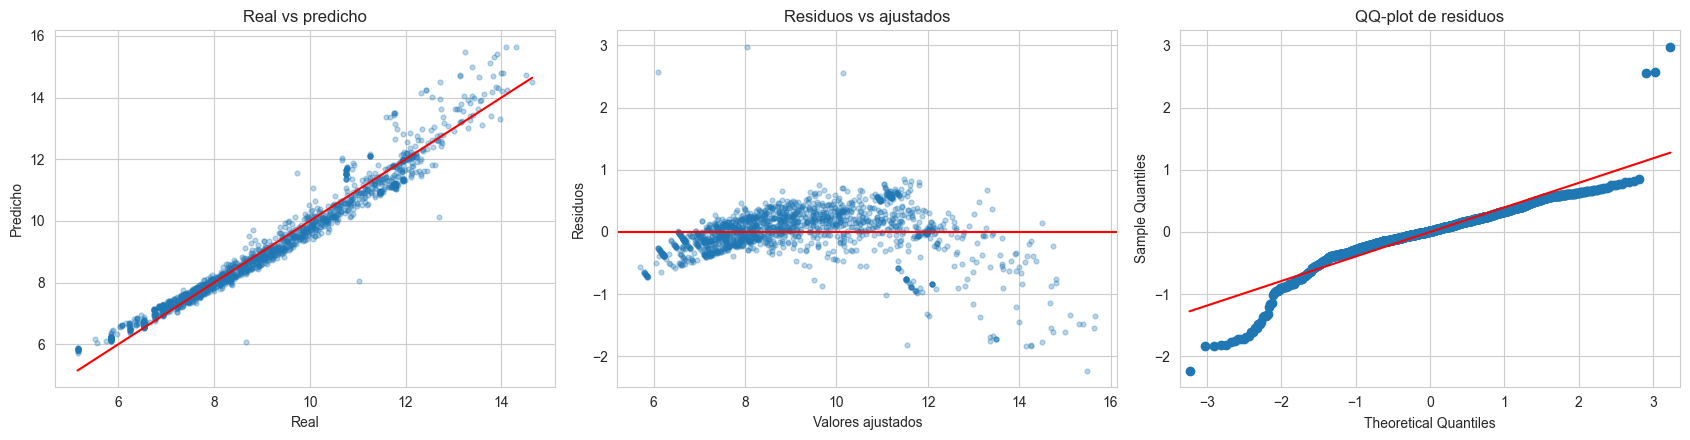

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(df["log_ingreso"], multiple.fittedvalues, alpha=0.3, s=12)
lim = [df["log_ingreso"].min(), df["log_ingreso"].max()]
ax[0].plot(lim, lim, color="red")
ax[0].set_xlabel("Real"); ax[0].set_ylabel("Predicho"); ax[0].set_title("Real vs predicho")

ax[1].scatter(multiple.fittedvalues, multiple.resid, alpha=0.3, s=12)
ax[1].axhline(0, color="red")
ax[1].set_xlabel("Valores ajustados"); ax[1].set_ylabel("Residuos"); ax[1].set_title("Residuos vs ajustados")

sm.qqplot(multiple.resid, line="s", ax=ax[2])
ax[2].set_title("QQ-plot de residuos")
plt.tight_layout(); plt.show()

### Comparación de coeficientes: simple vs múltiple

In [25]:
comp = pd.DataFrame({"Simple": simple.params, "Múltiple": multiple.params})
comp.loc["R2 ajustado"] = [simple.rsquared_adj, multiple.rsquared_adj]
comp.round(3)

,Simple,Múltiple
const,3.707,0.541
log_antiguedad,NaN,0.055
log_compras,NaN,0.318
log_precio_prom,0.730,0.809
log_unidades,NaN,0.898
R2 ajustado,0.558,0.961


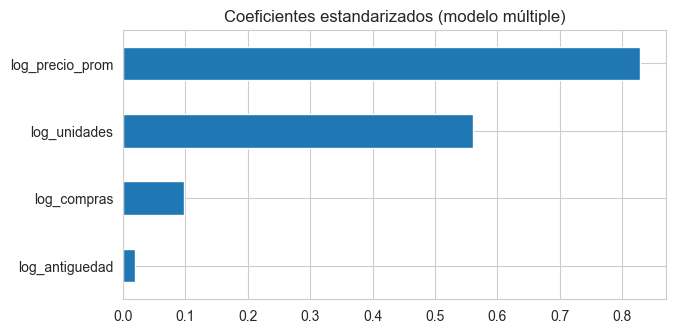

In [26]:
# coeficientes estandarizados del modelo múltiple para comparar el peso de cada variable
cc = sel + ["log_ingreso"]
z = (df[cc] - df[cc].mean()) / df[cc].std()
mz = sm.OLS(z["log_ingreso"], z[sel]).fit()
mz.params.sort_values().plot.barh(figsize=(7, 3.5))
plt.title("Coeficientes estandarizados (modelo múltiple)")
plt.show()

In [27]:
print(f"Coeficiente de {mejor}: simple = {simple.params[mejor]:.3f}, múltiple = {multiple.params[mejor]:.3f}")
print(f"R2 ajustado pasa de {simple.rsquared_adj:.3f} a {multiple.rsquared_adj:.3f}")

Coeficiente de log_precio_prom: simple = 0.730, múltiple = 0.809
R2 ajustado pasa de 0.558 a 0.961


El VIF eliminó `log_productos` (7.1) por su relación con `log_unidades`. Después, la eliminación hacia atrás quitó `log_recencia` y `log_marcas` por no ser significativas. El modelo final queda con `log_precio_prom`, `log_unidades`, `log_compras` y `log_antiguedad`.

Comparado con el simple:
- El coeficiente de `log_precio_prom` pasa de 0.730 a 0.809. En el simple ese coeficiente estaba mezclado con el efecto de otras variables; ahora se mide manteniendo constantes las unidades y las compras.
- El R² ajustado sube de 0.558 a 0.961 y el RMSE en prueba baja de 1.27 a 0.43, así que la mejora se mantiene fuera de la muestra de entrenamiento.
- Las variables que más pesan son `log_precio_prom` y `log_unidades`.

Una aclaración: el ingreso es en esencia precio por unidades, por lo que es normal que estas dos variables expliquen casi todo. El modelo sirve para describir cómo se compone el CLV, pero no es una predicción a futuro. En los residuos se ve algo de curvatura en los valores ajustados altos y unos pocos clientes mal ajustados, pero en general quedan cerca de cero.

## Regresión logística
### Variable dicotómica a predecir
Se define `inactivo`: el cliente no compra desde hace más de 180 días respecto a la última fecha del histórico. Es una variable desbalanceada, por lo que sirve para aplicar reponderación y oversampling.

In [28]:
df["inactivo"] = (df["recencia"] > 180).astype(int)
df["inactivo"].value_counts(normalize=True).round(3)

inactivo
0    0.753
1    0.247
Name: proportion, dtype: float64

### Variables predictoras dicotómicas
Las numéricas se dividen con la mediana (1 si está por encima). Las categóricas se resumen en 2 grupos tratando de que queden de tamaño parecido. `recencia` y `antiguedad` no se usan porque definen o limitan directamente la variable a predecir.

In [29]:
print(df.estado.value_counts(normalize=True).head(6).round(3))
print(df.marca_principal.value_counts(normalize=True).head(6).round(3))

estado
Ciudad de México    0.240
Estado de México    0.104
Puebla              0.101
Veracruz            0.042
Jalisco             0.030
Guanajuato          0.030
Name: proportion, dtype: float64
marca_principal
VITA      0.381
AIDITE    0.219
AG        0.169
MEDIT     0.104
JENSE     0.051
PHROZ     0.028
Name: proportion, dtype: float64


In [30]:
# categóricas a 2 grupos
centro = ["Ciudad de México", "Estado de México", "Puebla"]
df["zona_centro"] = df.estado.isin(centro).astype(int)
df["marca_vita"] = (df.marca_principal == "VITA").astype(int)

# numéricas con la mediana
for c in ["ingreso", "compras", "unidades", "productos", "marcas", "precio_prom"]:
    med = df[c].median()
    df["alto_" + c] = (df[c] > med).astype(int)
    print(c, "mediana =", med, "| proporción en 1:", round(df["alto_" + c].mean(), 2))

print("zona_centro:", round(df.zona_centro.mean(), 2), "| marca_vita:", round(df.marca_vita.mean(), 2))

ingreso mediana = 7200.0 | proporción en 1: 0.5
compras mediana = 1.0 | proporción en 1: 0.48
unidades mediana = 6.0 | proporción en 1: 0.45
productos mediana = 4.0 | proporción en 1: 0.46
marcas mediana = 1.0 | proporción en 1: 0.33
precio_prom mediana = 1121.7422556666666 | proporción en 1: 0.5
zona_centro: 0.44 | marca_vita: 0.38


Las medianas de `compras` y `marcas` son 1, por lo que el grupo alto significa más de una compra o más de una marca.

In [31]:
pred = ["zona_centro", "marca_vita", "alto_ingreso", "alto_compras", "alto_unidades",
        "alto_productos", "alto_marcas", "alto_precio_prom"]
print(df[pred].corr().round(2))
print(df.groupby("inactivo")[pred].mean().T.round(2))

                  zona_centro  marca_vita  alto_ingreso  alto_compras  alto_unidades  alto_productos  alto_marcas  alto_precio_prom
zona_centro              1.00        0.23         -0.17          0.04          -0.04           -0.01        -0.08             -0.24
marca_vita               0.23        1.00         -0.46         -0.01          -0.01            0.07        -0.24             -0.64
alto_ingreso            -0.17       -0.46          1.00          0.31           0.47            0.39         0.50              0.57
alto_compras             0.04       -0.01          0.31          1.00           0.60            0.57         0.47              0.03
alto_unidades           -0.04       -0.01          0.47          0.60           1.00            0.80         0.44              0.04
alto_productos          -0.01        0.07          0.39          0.57           0.80            1.00         0.44              0.03
alto_marcas             -0.08       -0.24          0.50          0.47       

`alto_unidades` y `alto_productos` están muy relacionadas (también se vio en el heatmap), así que se deja solo `alto_unidades` para evitar redundancia.

In [32]:
pred = ["zona_centro", "marca_vita", "alto_ingreso", "alto_compras", "alto_unidades",
        "alto_marcas", "alto_precio_prom"]
X = df[pred]
y = df["inactivo"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
print(ytr.value_counts(), yte.value_counts(), sep="\n")

inactivo
0    913
1    300
Name: count, dtype: int64
inactivo
0    305
1    100
Name: count, dtype: int64


### Modelo base (sin ajuste)

In [33]:
def evaluar(modelo, nombre):
    pr = modelo.predict(Xte)
    prob = modelo.predict_proba(Xte)[:, 1]
    rep = classification_report(yte, pr, output_dict=True, zero_division=0)
    return {"Modelo": nombre, "Accuracy": rep["accuracy"], "Precision (inactivo)": rep["1"]["precision"],
            "Recall (inactivo)": rep["1"]["recall"], "F1 (inactivo)": rep["1"]["f1-score"],
            "AUC": roc_auc_score(yte, prob)}

base = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
r_base = evaluar(base, "Sin ajuste")
r_base

{'Modelo': 'Sin ajuste',
 'Accuracy': 0.7530864197530864,
 'Precision (inactivo)': 0.0,
 'Recall (inactivo)': 0.0,
 'F1 (inactivo)': 0.0,
 'AUC': 0.7663278688524591}

### Reponderación de clases

In [34]:
pesos = LogisticRegression(max_iter=1000, class_weight="balanced").fit(Xtr, ytr)
r_pesos = evaluar(pesos, "Reponderación de clases")
r_pesos

{'Modelo': 'Reponderación de clases',
 'Accuracy': 0.674074074074074,
 'Precision (inactivo)': 0.41919191919191917,
 'Recall (inactivo)': 0.83,
 'F1 (inactivo)': 0.5570469798657718,
 'AUC': 0.7698360655737705}

### Oversampling
Se duplican al azar clientes de la clase minoritaria, solo en el conjunto de entrenamiento.

In [35]:
tr = pd.concat([Xtr, ytr], axis=1)
mayor = tr[tr.inactivo == 0]
menor = tr[tr.inactivo == 1]
menor_up = resample(menor, replace=True, n_samples=len(mayor), random_state=42)
tr_up = pd.concat([mayor, menor_up])
print(tr_up.inactivo.value_counts())

over = LogisticRegression(max_iter=1000).fit(tr_up[pred], tr_up["inactivo"])
r_over = evaluar(over, "Oversampling")
r_over

inactivo
0    913
1    913
Name: count, dtype: int64

{'Modelo': 'Oversampling',
 'Accuracy': 0.6765432098765433,
 'Precision (inactivo)': 0.4221105527638191,
 'Recall (inactivo)': 0.84,
 'F1 (inactivo)': 0.5618729096989966,
 'AUC': 0.7661967213114753}

### Comparación de los tres modelos

In [36]:
tabla = pd.DataFrame([r_base, r_pesos, r_over]).set_index("Modelo")
tabla.round(3)

,Accuracy,Precision (inactivo),Recall (inactivo),F1 (inactivo),AUC
Modelo,,,,,
Sin ajuste,0.753,0.000,0.00,0.000,0.766
Reponderación de clases,0.674,0.419,0.83,0.557,0.770
Oversampling,0.677,0.422,0.84,0.562,0.766


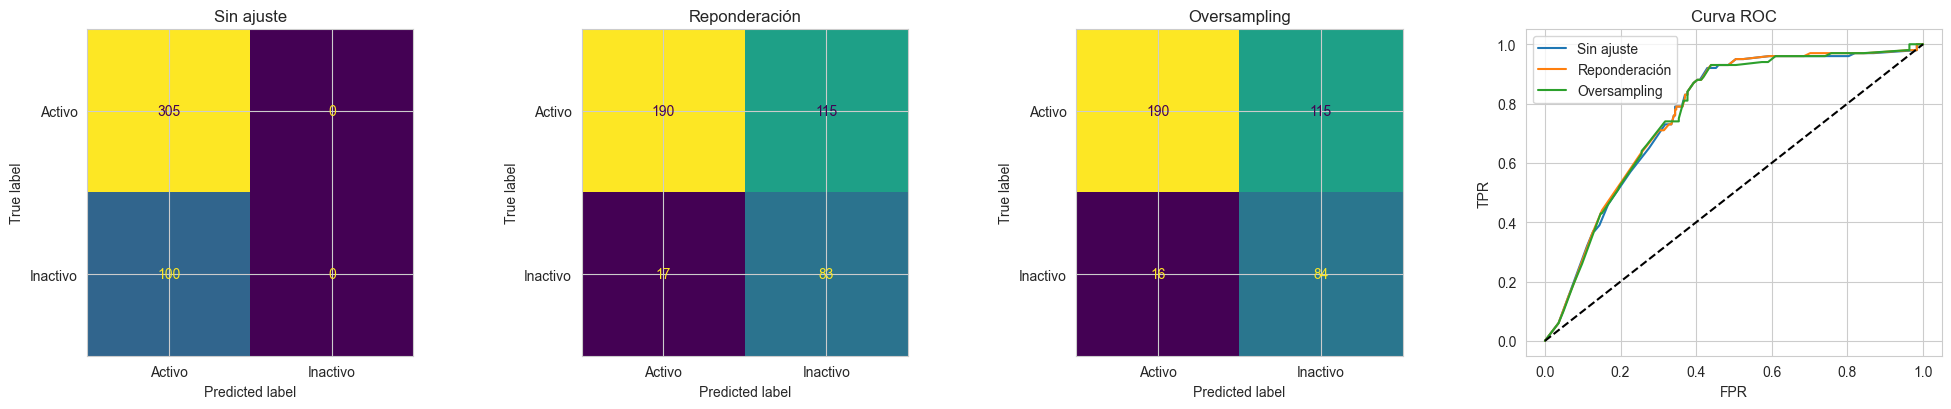

In [37]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for a, (m, n) in zip(ax[:3], [(base, "Sin ajuste"), (pesos, "Reponderación"), (over, "Oversampling")]):
    ConfusionMatrixDisplay(confusion_matrix(yte, m.predict(Xte)), display_labels=["Activo", "Inactivo"]).plot(ax=a, colorbar=False)
    a.set_title(n)
for m, n in [(base, "Sin ajuste"), (pesos, "Reponderación"), (over, "Oversampling")]:
    fpr, tpr, _ = roc_curve(yte, m.predict_proba(Xte)[:, 1])
    ax[3].plot(fpr, tpr, label=n)
ax[3].plot([0, 1], [0, 1], "k--")
ax[3].set_xlabel("FPR"); ax[3].set_ylabel("TPR"); ax[3].set_title("Curva ROC"); ax[3].legend()
plt.tight_layout(); plt.show()

El modelo sin ajuste tiene accuracy de 75%, pero es engañoso: predice a todos como activos (recall de 0 para inactivos), que es justo el problema del desbalance (25% inactivos).

Con reponderación de clases y con oversampling el recall de inactivos sube a 83% y 84%, a cambio de menor precisión y accuracy (alrededor de 67%). Los dos métodos dan resultados casi iguales (F1 de 0.56 en ambos). El AUC se queda en 0.77 en los tres, es decir, el ordenamiento de los clientes por riesgo es el mismo y lo que cambia es el punto de corte efectivo.

### Coeficientes y odds ratio (modelo con reponderación)

In [38]:
coef = pd.DataFrame({"coef": pesos.coef_[0], "odds_ratio": np.exp(pesos.coef_[0])}, index=pred)
coef.sort_values("coef").round(3)

,coef,odds_ratio
alto_compras,-1.082,0.339
alto_unidades,-0.627,0.534
alto_marcas,-0.221,0.801
marca_vita,-0.057,0.945
alto_precio_prom,-0.028,0.973
alto_ingreso,0.012,1.012
zona_centro,0.111,1.117


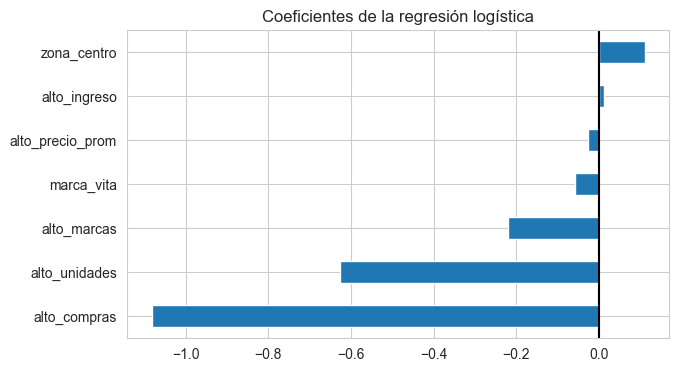

In [39]:
coef["coef"].sort_values().plot.barh(figsize=(7, 4))
plt.axvline(0, color="k")
plt.title("Coeficientes de la regresión logística")
plt.show()

In [40]:
# significancia con statsmodels (sin ajuste de clases)
logit = sm.Logit(ytr, sm.add_constant(Xtr)).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:               inactivo   No. Observations:                 1213
Model:                          Logit   Df Residuals:                     1205
Method:                           MLE   Df Model:                            7
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.09143
Time:                        11:57:04   Log-Likelihood:                -616.48
converged:                       True   LL-Null:                       -678.52
Covariance Type:            nonrobust   LLR p-value:                 1.085e-23
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.4637      0.185     -2.508      0.012      -0.826      -0.101
zona_centro          0.1883      0.145      1.295      0.195      -0.097       0.473
marca_vita          -0.0686 

Las variables que importan son `alto_compras` (odds ratio de 0.34) y `alto_unidades` (0.53): quien compró más de una vez tiene alrededor de 66% menos momios de estar inactivo. El resto (zona, marca principal, ingreso, precio, marcas) no es significativo en el modelo de statsmodels (p > 0.05). El pseudo R² es bajo (0.09), así que el modelo detecta algo de señal pero no es muy fuerte.

## Conclusiones

- Regresión simple: la variable más relacionada con el CLV es el precio promedio (r = 0.75, R² = 0.56), con una elasticidad de 0.73.
- Regresión múltiple: el mejor modelo usa precio promedio, unidades, compras y antigüedad, con R² ajustado de 0.96. El coeficiente del precio promedio sube a 0.81 al controlar por las otras variables. Como el ingreso se construye con precio y unidades, el modelo describe la composición del CLV más que predecirlo.
- Regresión logística: el 25% de los clientes está inactivo (más de 180 días sin comprar). Reponderar o hacer oversampling corrige el problema del modelo base, que no detectaba ningún inactivo, y logra un recall cercano a 84%. La recompra (más de una compra) y el volumen de unidades son los factores que más reducen la probabilidad de inactividad.
- Para el negocio: conviene dar seguimiento a los clientes de una sola compra, que son los más propensos a dejar de comprar.